# Signet Implementation

In [ ]:
!pip install -q mlflow dagshub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.2/44.2 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 98.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 120.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 95.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 kB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.8/222.8 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import dagshub
import mlflow
dagshub.init(repo_owner='maniyarabutalha00', repo_name='signet', mlflow=True)

❗❗❗ AUTHORIZATION REQUIRED ❗❗❗

Output()



Open the following link in your browser to authorize the client:
https://dagshub.com/login/oauth/authorize?state=68558ba7-fb94-478d-a6d4-d6bcfbb95669&client_id=32b60ba385aa7cecf24046d8195a71c07dd345d9657977863b52e7748e0f0f28&middleman_request_id=92a175e0b886f65286b65bda61668e45f1d7b74267972a19c9ece3ca30dbcb11




Accessing as maniyarabutalha00

Initialized MLflow to track repo "maniyarabutalha00/signet"

Repository maniyarabutalha00/signet initialized!

In [ ]:
mlflow.set_experiment("Signature Verification Experiments Presentation")

2026/09/25 05:34:26 INFO mlflow.tracking.fluent: Experiment with name 'Signature Verification Experiments Presentation' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/e9fe9155f1e54ef98f6bb6e7b4168fca', creation_time=1790314466826, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1790314466826, lifecycle_stage='active', name='Signature Verification Experiments Presentation', tags={}, trace_location=None, workspace='default'>

In [ ]:
mlflow.start_run(
    run_name="Selecting threshold based on the F1"
)

<ActiveRun: >

In [ ]:
import kagglehub
path = kagglehub.dataset_download("akashgundu/signature-verification-dataset")
data_dir = f"{path}/extract"

100%|██████████| 98.2M/98.2M [00:06<00:00, 16.0MB/s]

Extracting files...


In [ ]:
data_dir

'/root/.cache/kagglehub/datasets/akashgundu/signature-verification-dataset/versions/1/extract'

# creating all pairs possible

In [ ]:
import os

# Get only folders that are NOT _forg
ids = sorted([
    f for f in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, f))
    and not f.endswith("_forg")
])

ids2 = sorted([
    f for f in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, f))
    and f.endswith("_forg")
])

print("Total unique persons:", len(ids))
print("Person IDs:", ids)
print("Total unique persons:", len(ids2))
print("Person IDs:", ids2)

Total unique persons: 686
Person IDs: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '011', '012', '013', '014', '015', '016', '017', '018', '019', '020', '021', '022', '023', '024', '025', '026', '027', '028', '029', '030', '031', '032', '033', '034', '035', '036', '037', '038', '039', '040', '041', '042', '043', '044', '045', '046', '047', '048', '049', '050', '051', '052', '053', '054', '055', '056', '057', '058', '059', '060', '061', '062', '063', '064', '065', '066', '067', '068', '069', '070', '071', '072', '073', '074', '075', '076', '077', '078', '079', '080', '081', '082', '083', '084', '085', '086', '087', '088', '089', '090', '091', '092', '093', '094', '095', '096', '097', '098', '099', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '1

In [ ]:
import os
import random
import pandas as pd
from itertools import combinations

# ============================================================
# CONFIGURATION
# ============================================================

output_dir = os.path.join("splits")
os.makedirs(output_dir, exist_ok=True)

SEED = 42
random.seed(SEED)

# ============================================================
# 1. GET UNIQUE PERSON IDs
# ============================================================

# Only directories that are NOT _forg
ids = sorted([
    f for f in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, f))
    and not f.endswith("_forg")
])

print("Total unique persons:", len(ids))

# ============================================================
# 2. CHECK THAT WE HAVE 686 PERSONS
# ============================================================

if len(ids) != 686:
    print(f"WARNING: Expected 686 persons, but found {len(ids)} persons.")

# ============================================================
# 3. SHUFFLE PERSONS
# ============================================================

random.shuffle(ids)

# ============================================================
# 4. SPLIT PERSONS
# ============================================================

# 90% / 5% / 5%

VAL_SIZE = 34
TEST_SIZE = 34

test_ids = ids[:TEST_SIZE]

val_start = TEST_SIZE
val_end = TEST_SIZE + VAL_SIZE

val_ids = ids[val_start:val_end]

train_ids = ids[val_end:]

# ============================================================
# 5. VERIFY SPLIT SIZES
# ============================================================

print("\n========== PERSON SPLIT ==========")

print("Training persons  :", len(train_ids))
print("Validation persons:", len(val_ids))
print("Test persons      :", len(test_ids))
print("Total             :", len(train_ids) + len(val_ids) + len(test_ids))

# ============================================================
# 6. SAVE PERSON SPLITS
# ============================================================

pd.DataFrame({"person_id": train_ids}).to_csv(
    os.path.join(output_dir, "train_persons.csv"),
    index=False
)

pd.DataFrame({"person_id": val_ids}).to_csv(
    os.path.join(output_dir, "val_persons.csv"),
    index=False
)

pd.DataFrame({"person_id": test_ids}).to_csv(
    os.path.join(output_dir, "test_persons.csv"),
    index=False
)

# ============================================================
# 7. FUNCTION TO CREATE PAIRS
# ============================================================

def create_pairs(person_ids, split_name):

    pairs = []

    for person_id in sorted(person_ids):

        genuine_dir = os.path.join(data_dir, person_id)
        forged_dir = os.path.join(data_dir, person_id + "_forg")

        # ----------------------------------------------------
        # Check directories
        # ----------------------------------------------------

        if not os.path.isdir(genuine_dir):
            print(f"WARNING: Missing genuine folder: {person_id}")
            continue

        if not os.path.isdir(forged_dir):
            print(f"WARNING: Missing forged folder: {person_id}_forg")
            continue

        # ----------------------------------------------------
        # Get JPG genuine images
        # ----------------------------------------------------

        genuine_images = sorted([
            f for f in os.listdir(genuine_dir)
            if f.lower().endswith(".jpg")
        ])

        # ----------------------------------------------------
        # Get JPG forged images
        # ----------------------------------------------------

        forged_images = sorted([
            f for f in os.listdir(forged_dir)
            if f.lower().endswith(".jpg")
        ])

        # ----------------------------------------------------
        # Genuine-Genuine pairs
        # Label = 0
        # ----------------------------------------------------

        for img1, img2 in combinations(genuine_images, 2):

            pairs.append([
                f"{person_id}/{img1}",
                f"{person_id}/{img2}",
                0
            ])

        # ----------------------------------------------------
        # Genuine-Forged pairs
        # Label = 1
        # ----------------------------------------------------

        for genuine_img in genuine_images:

            for forged_img in forged_images:

                pairs.append([
                    f"{person_id}/{genuine_img}",
                    f"{person_id}_forg/{forged_img}",
                    1
                ])

    # --------------------------------------------------------
    # Create DataFrame
    # --------------------------------------------------------

    df = pd.DataFrame(
        pairs,
        columns=["image1", "image2", "label"]
    )

    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------

    output_csv = os.path.join(
        output_dir,
        f"{split_name}_pairs.csv"
    )

    df.to_csv(output_csv, index=False)

    print(f"\n{split_name.upper()}")
    print("-----------------------------")
    print("Persons:", len(person_ids))
    print("Total pairs:", len(df))

    if len(df) > 0:
        print("Genuine-Genuine pairs:",
              (df["label"] == 0).sum())

        print("Genuine-Forged pairs:",
              (df["label"] == 1).sum())

    print("Saved:", output_csv)

    return df


# ============================================================
# 8. CREATE PAIRS WITHIN EACH SPLIT
# ============================================================

train_pairs = create_pairs(
    train_ids,
    "train"
)

val_pairs = create_pairs(
    val_ids,
    "validation"
)

test_pairs = create_pairs(
    test_ids,
    "test"
)

# ============================================================
# 9. FINAL VERIFICATION
# ============================================================

print("\n======================================")
print("FINAL DATASET SUMMARY")
print("======================================")

print("Training persons  :", len(train_ids))
print("Validation persons:", len(val_ids))
print("Test persons      :", len(test_ids))

print("\nTraining pairs    :", len(train_pairs))
print("Validation pairs  :", len(val_pairs))
print("Test pairs        :", len(test_pairs))

print("\nDone!")

Total unique persons: 686

========== PERSON SPLIT ==========
Training persons  : 618
Validation persons: 34
Test persons      : 34
Total             : 686

TRAIN
-----------------------------
Persons: 618
Total pairs: 102308
Genuine-Genuine pairs: 31905
Genuine-Forged pairs: 70403
Saved: splits/train_pairs.csv

VALIDATION
-----------------------------
Persons: 34
Total pairs: 5727
Genuine-Genuine pairs: 1791
Genuine-Forged pairs: 3936
Saved: splits/validation_pairs.csv

TEST
-----------------------------
Persons: 34
Total pairs: 5612
Genuine-Genuine pairs: 1750
Genuine-Forged pairs: 3862
Saved: splits/test_pairs.csv

FINAL DATASET SUMMARY
Training persons  : 618
Validation persons: 34
Test persons      : 34

Training pairs    : 102308
Validation pairs  : 5727
Test pairs        : 5612

Done!


In [ ]:
mlflow.log_params({
    "split_ratio": "90/5/5",
    "training_persons": len(train_ids),
    "validation_persons": len(val_ids),
    "test_persons": len(test_ids)
})

mlflow.log_metrics({
    "training_pairs": len(train_pairs),
    "validation_pairs": len(val_pairs),
    "test_pairs": len(test_pairs)
})

print("Dataset split information logged to MLflow!")

Dataset split information logged to MLflow!


# All Pairs

In [ ]:
train_pairs

,image1,image2,label
0,001/1-001_01.jpg,001/1-001_010.jpg,0
1,001/1-001_01.jpg,001/1-001_02.jpg,0
2,001/1-001_01.jpg,001/1-001_03.jpg,0
3,001/1-001_01.jpg,001/1-001_04.jpg,0
4,001/1-001_01.jpg,001/1-001_05.jpg,0
...,...,...,...
102303,686/94.jpg,686_forg/55.jpg,1
102304,686/94.jpg,686_forg/65.jpg,1
102305,686/94.jpg,686_forg/75.jpg,1
102306,686/94.jpg,686_forg/85.jpg,1


In [ ]:
val_pairs

,image1,image2,label
0,015/6-004_01.jpg,015/6-004_010.jpg,0
1,015/6-004_01.jpg,015/6-004_02.jpg,0
2,015/6-004_01.jpg,015/6-004_03.jpg,0
3,015/6-004_01.jpg,015/6-004_04.jpg,0
4,015/6-004_01.jpg,015/6-004_05.jpg,0
...,...,...,...
5722,649/95.jpg,649_forg/51.jpg,1
5723,649/95.jpg,649_forg/61.jpg,1
5724,649/95.jpg,649_forg/71.jpg,1
5725,649/95.jpg,649_forg/81.jpg,1


In [ ]:
test_pairs

,image1,image2,label
0,003/1-005_01.jpg,003/1-005_010.jpg,0
1,003/1-005_01.jpg,003/1-005_02.jpg,0
2,003/1-005_01.jpg,003/1-005_03.jpg,0
3,003/1-005_01.jpg,003/1-005_04.jpg,0
4,003/1-005_01.jpg,003/1-005_05.jpg,0
...,...,...,...
5607,632/91.jpg,632_forg/52.jpg,1
5608,632/91.jpg,632_forg/62.jpg,1
5609,632/91.jpg,632_forg/72.jpg,1
5610,632/91.jpg,632_forg/82.jpg,1


In [ ]:
train_df = train_pairs
val_df = val_pairs
test_df = test_pairs
print("Train:", len(train_df))
print("Val:", len(val_df))
print("Test:", len(test_df))

Train: 102308
Val: 5727
Test: 5612


###Imports

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from PIL import Image, UnidentifiedImageError
import torchvision.transforms as transforms

###Dataset loading

In [ ]:
image_dir = data_dir

transform = transforms.Compose([
    transforms.Resize((155,220)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [ ]:
class SiameseDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __getitem__(self, index):

        img1_rel = self.df.iloc[index, 0]
        img2_rel = self.df.iloc[index, 1]

        img1_path = os.path.join(self.image_dir, img1_rel)
        img2_path = os.path.join(self.image_dir, img2_rel)

        try:
          img1 = Image.open(img1_path).convert("L")
          img2 = Image.open(img2_path).convert("L")
        except UnidentifiedImageError:
          # pick another sample if image is broken
          return self.__getitem__((index + 1) % len(self.df))

        if self.transform:
            img1 = self.transform(img1)
            img2 = self.transform(img2)

        label = torch.tensor(self.df.iloc[index, 2], dtype=torch.float32).unsqueeze(0)

        return img1, img2, label

    def __len__(self):
        return len(self.df)

In [ ]:
train_dataset = SiameseDataset(train_df, image_dir, transform)
val_dataset = SiameseDataset(val_df, image_dir, transform)
test_dataset = SiameseDataset(test_df, image_dir, transform)

In [ ]:
batch_size = 16

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,num_workers=2,pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,num_workers=2,pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,num_workers=2,pin_memory=True)

##Siamese

In [ ]:
class SiameseNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1,1))

        self.embedding = nn.Sequential(
            nn.Linear(256,256),
            nn.ReLU(),
            nn.Linear(256,128),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward_once(self,x):

        x = self.features(x)
        x = self.pool(x)
        x = x.view(x.size(0),-1)

        embedding = self.embedding(x)

        return embedding


    def forward(self,x1,x2):

        e1 = self.forward_once(x1)
        e2 = self.forward_once(x2)

        diff = torch.abs(e1 - e2)
        product = e1 * e2
        x = torch.cat([diff,product], dim=1)
        out = self.classifier(x)

        return out

# Model Setup

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SiameseNetwork().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

In [ ]:
# ============================================================
# MLFLOW - LOG HYPERPARAMETERS
# ============================================================

mlflow.log_params({
    "image_height": 155,
    "image_width": 220,

    "embedding_dim": 128,

    "batch_size": batch_size,
    "learning_rate": 3e-4,
    "weight_decay": 1e-4,

    "optimizer": "Adam",
    "loss_function": "BCEWithLogitsLoss",

    "dropout": 0.3,
    "max_epochs": 20,
    "early_stopping_patience": 3,

    "random_seed": 42
})

print("Hyperparameters logged to MLflow!")

Hyperparameters logged to MLflow!


# Train Function

In [ ]:
def train_one_epoch(loader):

    model.train()
    running_loss = 0

    for img1,img2,label in loader:

        img1 = img1.to(device)
        img2 = img2.to(device)
        label = label.to(device)

        optimizer.zero_grad()

        logits = model(img1,img2)

        loss = criterion(logits,label)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    return running_loss/len(loader)

# Validation Function

In [ ]:
def evaluate(loader):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for img1,img2,label in loader:

            img1 = img1.to(device)
            img2 = img2.to(device)
            label = label.to(device)

            logits = model(img1,img2)

            loss = criterion(logits,label)

            total_loss += loss.item()

    return total_loss/len(loader)

# training and validation

In [ ]:
best_val_loss = float("inf")
patience = 3
counter = 0

train_losses = []
val_losses = []

for epoch in range(20):

    # ---------------- TRAIN ----------------
    model.train()
    train_loss = 0.0

    for img1, img2, label in train_loader:

        img1 = img1.to(device)
        img2 = img2.to(device)
        label = label.to(device)

        optimizer.zero_grad()

        outputs = model(img1, img2)
        loss = criterion(outputs, label)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)


    # ---------------- VALIDATION ----------------
    model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for img1, img2, label in val_loader:

            img1 = img1.to(device)
            img2 = img2.to(device)
            label = label.to(device)

            outputs = model(img1, img2)
            loss = criterion(outputs, label)

            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)


    print(
        f"Epoch {epoch+1}/20 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )


    # ---------------- EARLY STOPPING ----------------
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        counter = 0

        torch.save(
            model.state_dict(),
            "best_model.pth"
        )

    else:

        counter += 1

        if counter >= patience:
            print("Early stopping")
            break

Epoch 1/20 | Train Loss: 0.4842 | Val Loss: 0.4438
Epoch 2/20 | Train Loss: 0.3276 | Val Loss: 0.4192
Epoch 3/20 | Train Loss: 0.1992 | Val Loss: 0.5003
Epoch 4/20 | Train Loss: 0.1114 | Val Loss: 0.6700
Epoch 5/20 | Train Loss: 0.0677 | Val Loss: 0.8441
Early stopping


# Load Model

In [ ]:
#model = SiameseNetwork().to(device)
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

SiameseNetwork(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=

In [ ]:
# ============================================================
# MLFLOW - LOG BEST MODEL
# ============================================================

mlflow.log_artifact(
    "best_model.pth",
    artifact_path="models"
)

print("Best PyTorch model logged to MLflow!")

Best PyTorch model logged to MLflow!


# Training Loss and Validation Loss Graph

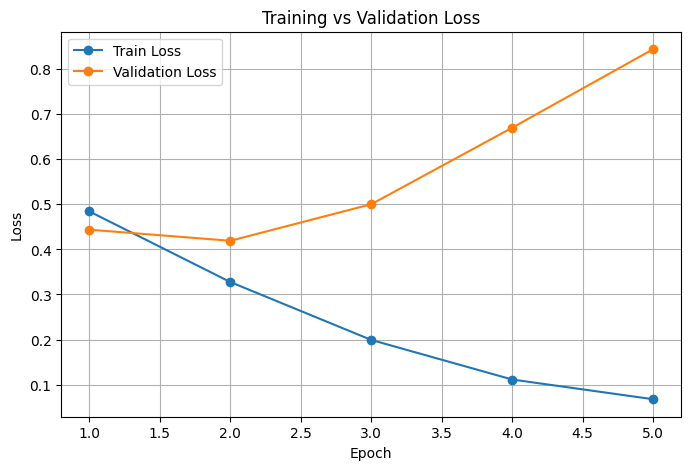

In [ ]:
import matplotlib.pyplot as plt
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker='o', label="Train Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig("training_curve.png", bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# MLFLOW - LOG LOSS CURVE
# ============================================================

mlflow.log_artifact(
    "training_curve.png",
    artifact_path="plots/training"
)

print("Training curve logged to MLflow!")

Training curve logged to MLflow!


# Additional

In [ ]:
# ============================================================
# GET TRUE LABELS + PROBABILITIES
# ============================================================

import numpy as np

def get_labels_and_probabilities(loader):

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():

        for img1, img2, label in loader:

            img1 = img1.to(device)
            img2 = img2.to(device)

            logits = model(img1, img2)

            probs = torch.sigmoid(logits)

            all_labels.extend(
                label.cpu().numpy().flatten()
            )

            all_probs.extend(
                probs.cpu().numpy().flatten()
            )

    return (
        np.array(all_labels),
        np.array(all_probs)
    )

In [ ]:
# ============================================================
# FAR / FRR THRESHOLD ANALYSIS - VALIDATION SET
# ============================================================

from sklearn.metrics import confusion_matrix
import numpy as np

y_val_true, y_val_probs = get_labels_and_probabilities(
    val_loader
)

thresholds = np.arange(
    0.01,
    1.00,
    0.01
)

far_values = []
frr_values = []

for threshold in thresholds:

    y_val_pred = (
        y_val_probs >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_val_true,
        y_val_pred,
        labels=[0, 1]
    )

    TN, FP, FN, TP = cm.ravel()

    # Label 1 = Forged
    #
    # FAR:
    # forged signature incorrectly accepted as genuine
    FAR = FN / (FN + TP) if (FN + TP) > 0 else 0

    # FRR:
    # genuine signature incorrectly rejected as forged
    FRR = FP / (TN + FP) if (TN + FP) > 0 else 0

    far_values.append(FAR)
    frr_values.append(FRR)

far_values = np.array(far_values)
frr_values = np.array(frr_values)

print("Threshold analysis completed!")

Threshold analysis completed!


In [ ]:
# ============================================================
# FIND OPTIMAL THRESHOLD USING VALIDATION F1
# ============================================================

from sklearn.metrics import f1_score

f1_values = []

for threshold in thresholds:

    y_val_pred = (
        y_val_probs >= threshold
    ).astype(int)

    f1 = f1_score(
        y_val_true,
        y_val_pred,
        pos_label=1
    )

    f1_values.append(f1)

f1_values = np.array(f1_values)

best_index = np.argmax(f1_values)

optimal_threshold = thresholds[best_index]

optimal_f1 = f1_values[best_index]
optimal_far = far_values[best_index]
optimal_frr = frr_values[best_index]

print("===================================")
print("OPTIMAL VALIDATION THRESHOLD")
print("===================================")

print(
    f"Threshold : {optimal_threshold:.2f}"
)

print(
    f"F1 Score  : {optimal_f1:.4f}"
)

print(
    f"FAR       : {optimal_far * 100:.2f}%"
)

print(
    f"FRR       : {optimal_frr * 100:.2f}%"
)

OPTIMAL VALIDATION THRESHOLD
Threshold : 0.33
F1 Score  : 0.8745
FAR       : 10.37%
FRR       : 33.78%


In [ ]:
# ============================================================
# MLFLOW - LOG OPTIMAL THRESHOLD
# ============================================================

mlflow.log_param(
    "threshold_selection_method",
    "max_validation_f1"
)

mlflow.log_metric(
    "optimal_threshold",
    float(optimal_threshold)
)

mlflow.log_metric(
    "validation_f1_at_optimal_threshold",
    float(optimal_f1)
)

mlflow.log_metric(
    "validation_far_at_optimal_threshold",
    float(optimal_far)
)

mlflow.log_metric(
    "validation_frr_at_optimal_threshold",
    float(optimal_frr)
)

print("Optimal threshold logged to MLflow!")

Optimal threshold logged to MLflow!


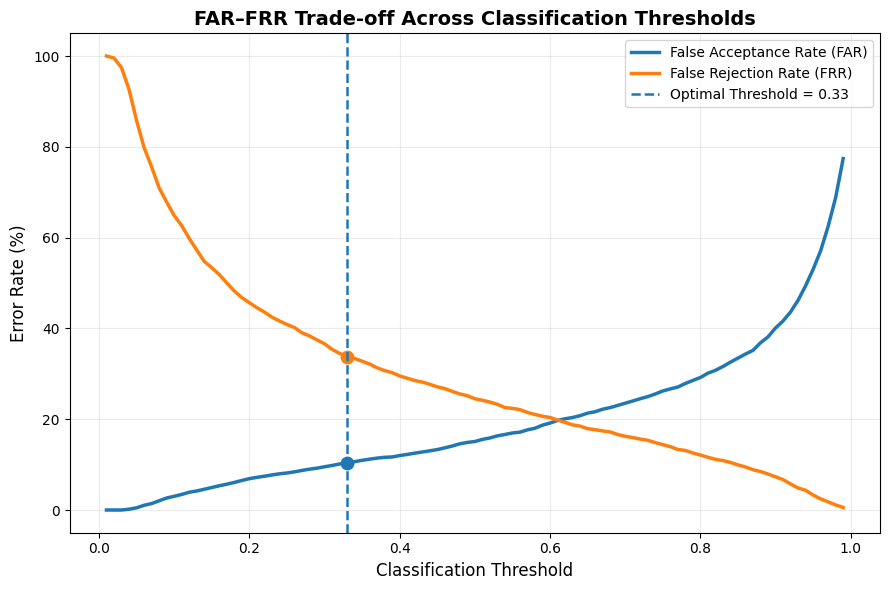

In [ ]:
# ============================================================
# FAR / FRR CURVE
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    thresholds,
    np.array(far_values) * 100,
    linewidth=2.5,
    label="False Acceptance Rate (FAR)"
)

plt.plot(
    thresholds,
    np.array(frr_values) * 100,
    linewidth=2.5,
    label="False Rejection Rate (FRR)"
)

plt.axvline(
    optimal_threshold,
    linestyle="--",
    linewidth=1.8,
    label=f"Optimal Threshold = {optimal_threshold:.2f}"
)

plt.scatter(
    optimal_threshold,
    optimal_far * 100,
    s=80
)

plt.scatter(
    optimal_threshold,
    optimal_frr * 100,
    s=80
)

plt.xlabel(
    "Classification Threshold",
    fontsize=12
)

plt.ylabel(
    "Error Rate (%)",
    fontsize=12
)

plt.title(
    "FAR–FRR Trade-off Across Classification Thresholds",
    fontsize=14,
    fontweight="bold"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "far_frr_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
mlflow.log_artifact(
    "far_frr_curve.png",
    artifact_path="plots/evaluation"
)

print("FAR / FRR curve logged!")

FAR / FRR curve logged!


# Test/Evaluation

In [ ]:
# ============================================================
# FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_test_true, y_test_probs = get_labels_and_probabilities(
    test_loader
)

y_test_pred = (
    y_test_probs >= optimal_threshold
).astype(int)

test_accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

test_precision = precision_score(
    y_test_true,
    y_test_pred,
    pos_label=1
)

test_recall = recall_score(
    y_test_true,
    y_test_pred,
    pos_label=1
)

test_f1 = f1_score(
    y_test_true,
    y_test_pred,
    pos_label=1
)

cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=[0, 1]
)

TN, FP, FN, TP = cm.ravel()

test_far = (
    FN / (FN + TP)
    if (FN + TP) > 0
    else 0
)

test_frr = (
    FP / (TN + FP)
    if (TN + FP) > 0
    else 0
)

print("================================")
print("FINAL TEST RESULTS")
print("================================")

print(f"Threshold : {optimal_threshold:.2f}")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"FAR       : {test_far * 100:.2f}%")
print(f"FRR       : {test_frr * 100:.2f}%")

FINAL TEST RESULTS
Threshold : 0.33
Accuracy  : 0.8541
Precision : 0.8601
Recall    : 0.9410
F1 Score  : 0.8987
FAR       : 5.90%
FRR       : 33.77%


In [ ]:
# ============================================================
# MLFLOW - LOG FINAL TEST METRICS
# ============================================================

mlflow.log_metrics({
    "test_accuracy": float(test_accuracy),

    "test_precision_forged": float(test_precision),

    "test_recall_forged": float(test_recall),

    "test_f1_forged": float(test_f1),

    "test_far": float(test_far),

    "test_frr": float(test_frr)
})

print("Final test metrics logged to MLflow!")

Final test metrics logged to MLflow!


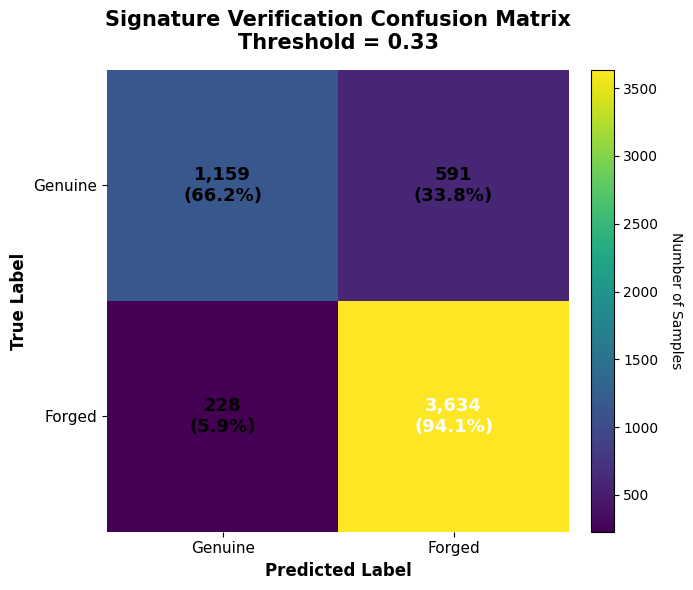

In [ ]:
# ============================================================
# BEAUTIFUL CONFUSION MATRIX - MATPLOTLIB ONLY
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "Genuine",
    "Forged"
]

fig, ax = plt.subplots(
    figsize=(7, 6)
)

im = ax.imshow(cm)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(len(class_names))
)

ax.set_yticks(
    np.arange(len(class_names))
)

ax.set_xticklabels(
    class_names,
    fontsize=11
)

ax.set_yticklabels(
    class_names,
    fontsize=11
)

ax.set_xlabel(
    "Predicted Label",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "True Label",
    fontsize=12,
    fontweight="bold"
)

ax.set_title(
    f"Signature Verification Confusion Matrix\n"
    f"Threshold = {optimal_threshold:.2f}",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# ------------------------------------------------------------
# Add values + percentages
# ------------------------------------------------------------

row_sums = cm.sum(
    axis=1,
    keepdims=True
)

percentages = (
    cm / row_sums
) * 100

threshold_color = cm.max() / 2

for i in range(cm.shape[0]):

    for j in range(cm.shape[1]):

        text = (
            f"{cm[i, j]:,}\n"
            f"({percentages[i, j]:.1f}%)"
        )

        ax.text(
            j,
            i,
            text,
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color=(
                "white"
                if cm[i, j] > threshold_color
                else "black"
            )
        )

# ------------------------------------------------------------
# Color bar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.ax.set_ylabel(
    "Number of Samples",
    rotation=270,
    labelpad=18
)

# ------------------------------------------------------------
# Remove unnecessary borders
# ------------------------------------------------------------

for edge in [
    "top",
    "right",
    "left",
    "bottom"
]:
    ax.spines[edge].set_visible(False)

plt.tight_layout()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# MLFLOW - LOG CONFUSION MATRIX
# ============================================================

mlflow.log_artifact(
    "confusion_matrix.png",
    artifact_path="plots/evaluation"
)

print("Confusion matrix logged to MLflow!")

Confusion matrix logged to MLflow!


In [ ]:
mlflow.end_run()

🏃 View run Selecting threshold based on the F1 at: https://dagshub.com/maniyarabutalha00/signet.mlflow/#/experiments/0/runs/1336d80241fb4fe1bdc3cf16ff57dd1c
🧪 View experiment at: https://dagshub.com/maniyarabutalha00/signet.mlflow/#/experiments/0
